# Projet complexité 2026

- Rémy CARUHEL
- Timothée MEYER

Détection de communautés dans les graphes.

## Usage de l'intelligence artificielle

Conformément aux consignes, nous signalons ci-dessous tous les endroits du projet
où une IA générative a été utilisée.

| Section | Outil  | Nature de l'assistance                                                                          |
|---|--------|-------------------------------------------------------------------------------------------------|
| 1.2 Rappels de complexité | —      | Aucune                                                                                          |
| 2.1 Générateur de graphes | Gemini | Génération de code pour compléter le code existant pour implémenter les couleurs par communauté |
| 2.2 Girvan-Newman | —      | À compléter                                                                                     |
| 2.3 Louvain | —      | À compléter                                                                                     |
| 2.4 Propagation d'étiquettes | —      | À compléter                                                                                     |
| 4 Comparaisons | —      | À compléter                                                                                     |

Tout code issu d'une IA a été relu, testé et commenté par le binôme.

## 1. Introduction

### 1.1 Objet du projet

Ce projet porte sur la détection de communautés dans les graphes. Étant donné un
graphe, on cherche à partitionner ses sommets en groupes denses en interne et
faiblement connectés entre eux. La qualité d'une partition est le plus souvent
mesurée par la modularité, dont la maximisation exacte est un problème
NP-difficile. Les algorithmes que nous étudions sont donc des heuristiques,
dont les performances théoriques et empiriques diffèrent fortement.

L'objectif est de comparer ces heuristiques sur des graphes synthétiques et
réels, en reliant leurs comportements observés à leur complexité théorique.


<img src="Graphe-Clustering.png" width="500"/>

*Figure 1. Exemple de partition d'un graphe en communautés. Les sommets d'une
même communauté sont denses en interne et peu connectés au reste du graphe.*

### 1.2 Remarque sur l'usage des bibliothèques

Les algorithmes de détection de communautés sont disponibles dans des
bibliothèques telles que NetworkX. Vous pouvez les utiliser directement ou en
écrire votre propre version : ce choix n'entre pas dans l'évaluation. En
revanche, pour chaque algorithme étudié, vous devez être capables d'expliquer
son principe et de montrer que vous l'avez compris, en illustrant à la main
une itération complète sur une petite instance, avec les calculs
intermédiaires.

### 1.3 Rappels de complexité

La complexité d'un algorithme décrit la croissance des ressources consommées
(temps, mémoire) en fonction de la taille de l'entrée. On distingue les
problèmes polynomiaux, pour lesquels il existe un algorithme dont le temps
d'exécution est borné par un polynôme en la taille de l'entrée, et les
problèmes NP-difficiles, pour lesquels aucun algorithme polynomial connu
n'existe à ce jour.


[... compléter les définitions, et exemples chiffrés par exemple en comparant deux complexités ...]



In [7]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import time
import random

from projet_A2026_utils import (
    generate_planted_partition_graph,
    load_real_graph,
    girvan_newman_communities,
    louvain_communities,
    label_propagation_communities_simple,
    label_propagation_communities_stabilized,
    exact_modularity_maximization,
    modularity,
    plot_communities,
    benchmark_communities,
)

np.random.seed(0)
random.seed(0)

## 2. Algorithmes de détection de communautés

### 2.1 Le problème et la modularité

Soit $G = (V, E)$ un graphe non orienté, $A$ sa matrice d'adjacence, $k_i$ le
degré du sommet $i$ et $m$ le nombre d'arêtes. La modularité d'une partition
$\mathcal{C}$ est définie par

$$
Q(\mathcal{C}) = \frac{1}{2m} \sum_{i,j}
\left( A_{ij} - \frac{k_i k_j}{2m} \right) \delta(c_i, c_j)
$$

où $c_i$ désigne la communauté du sommet $i$ et $\delta$ le symbole de
Kronecker. La valeur de $Q$ est comprise entre $-1$ et $1$ ; elle est positive
lorsque la partition capture mieux que le hasard la structure du graphe.

**On a aussi pour le calcul de la modularité :**

$$
Q = \sum_{c=1}^{n}
       \left[ \frac{L_c}{m} - \gamma\left( \frac{k_c}{2m} \right) ^2 \right]
$$

où la somme porte sur l'ensemble des communautés $c$, $m$ est le nombre total d'arêtes,
$L_c$ est le nombre d'arêtes internes à la communauté $c$,
$k_c$ est la somme des degrés des sommets de la communauté $c$,
et $\gamma$ est le paramètre de résolution.

*Source:*
https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.community.quality.modularity.html#networkx.algorithms.community.quality.modularity

Maximiser $Q$ sur l'ensemble des partitions est un problème NP-difficile.
Les algorithmes présentés ci-dessous sont donc des heuristiques.

### 2.2 Girvan-Newman

**Principe.** L'algorithme supprime itérativement l'arête de plus forte
betweenness, c'est-à-dire celle qui est traversée par le plus grand nombre de
plus courts chemins. Les arêtes reliant deux communautés ont une betweenness
élevée et disparaissent en premier, ce qui fait éclater progressivement les
communautés.

**Complexité.** Le calcul des betweenness coûte $O(n \cdot m)$ par itération,
et il y a $m$ itérations, soit $O(n \cdot m^2)$ dans la version naïve.

**Illustration manuelle d'une itération.**

**Calcul de betweenness**
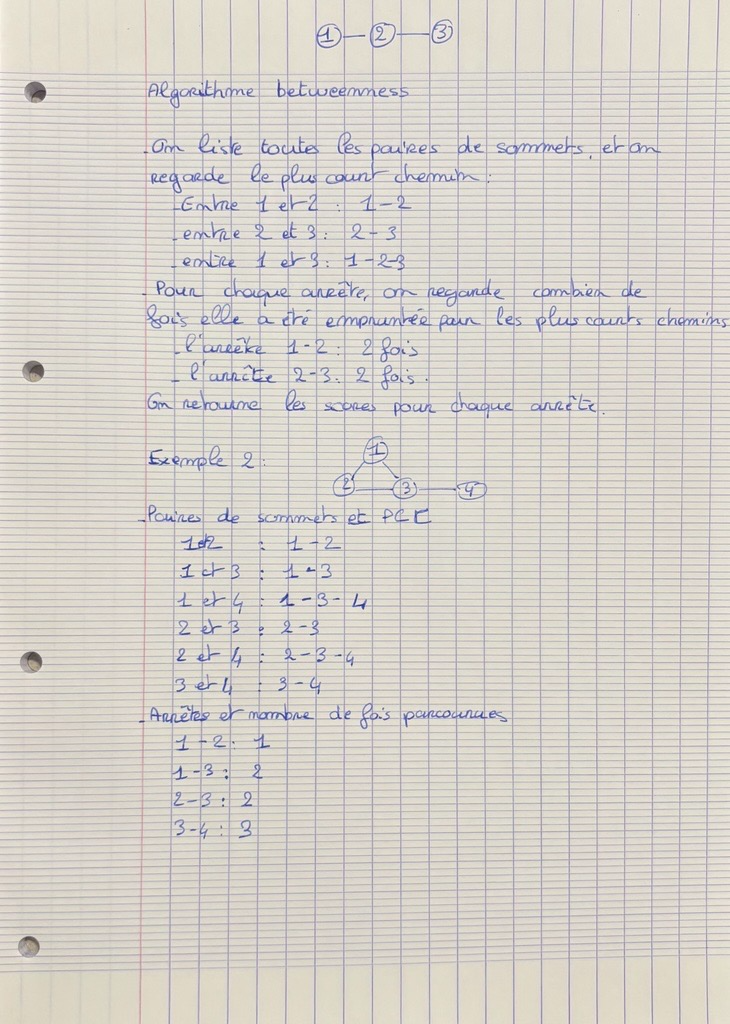

**Algorithme Grivan-Newman**
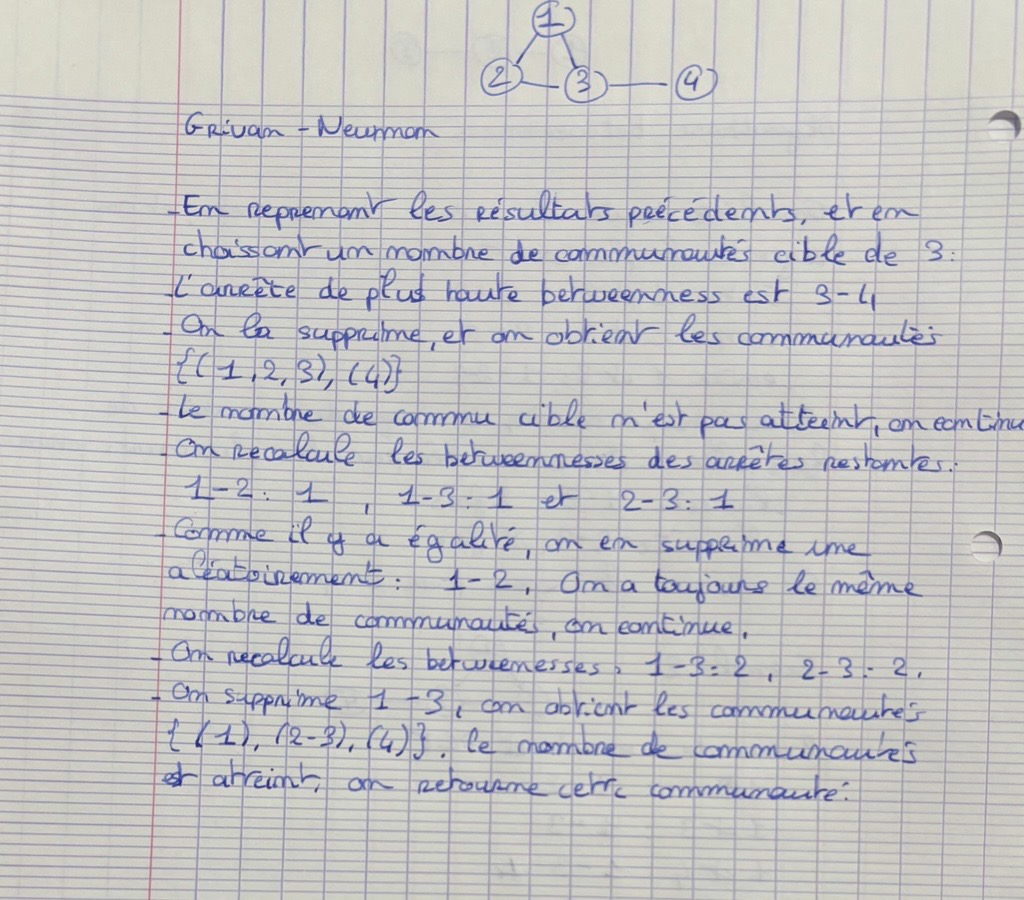

### 2.3 Louvain

**Principe.** L'algorithme alterne deux phases. Dans la première, chaque sommet
est déplacé vers la communauté voisine qui augmente le plus la modularité, et
ce jusqu'à stabilisation. Dans la seconde, chaque communauté est contractée en
un super-sommet, et on recommence. L'algorithme s'arrête lorsqu'aucun gain de
modularité n'est possible.

**Complexité.** Quasi-linéaire en pratique, $O(m \log n)$ sur la plupart des
graphes réels.

**Illustration manuelle d'une itération.**



### 2.4 Propagation d'étiquettes

**Principe.** Chaque sommet reçoit initialement une étiquette unique. À chaque
itération, chaque sommet adopte l'étiquette majoritaire chez ses voisins, les
égalités étant tranchées aléatoirement. L'algorithme converge lorsque les
étiquettes se stabilisent.

**Complexité.** Chaque itération coûte $O(m)$, et le nombre d'itérations est
en pratique petit, ce qui donne une complexité quasi-linéaire.

**Illustration manuelle d'une itération.**

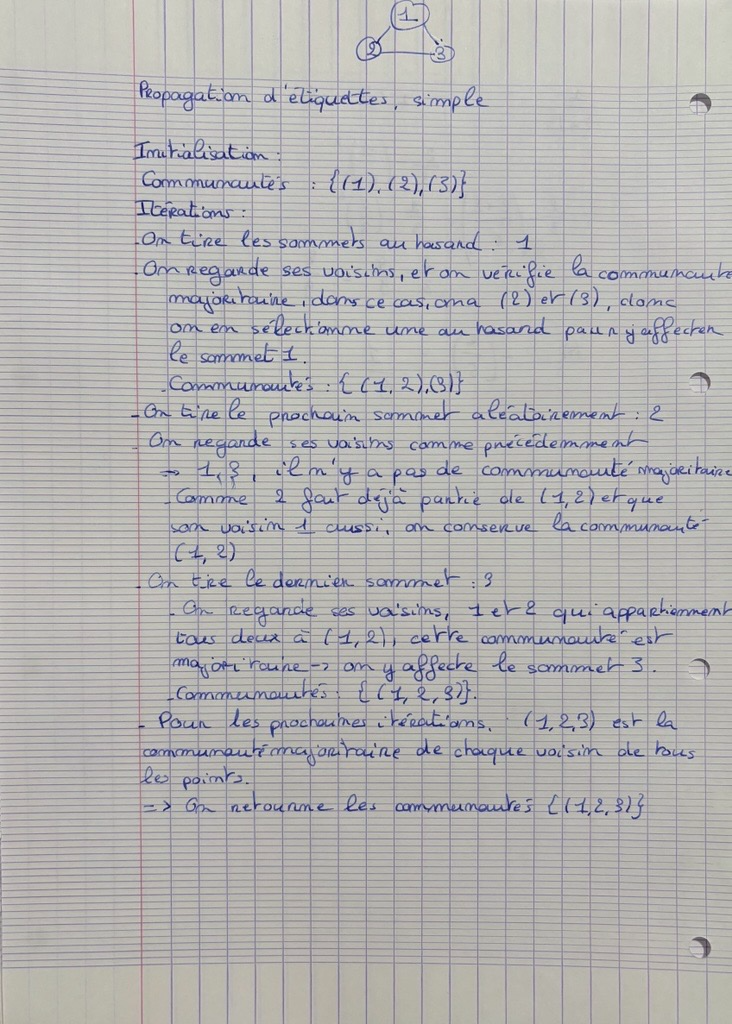

### 2.5 Partition de modularité maximale (Méthode exacte)

**Principe.** L'algorithme résout le problème d'optimisation combinatoire exact en énumérant
de manière exhaustive toutes les partitions possibles de l'ensemble des sommets $V$, sans doublon,
grâce à un parcours en profondeur avec retour sur trace (*backtracking*). Chaque sommet est assigné
successivement soit à une communauté déjà existante, soit à une nouvelle communauté. Pour chaque
partition candidate générée, la modularité $Q$ est calculée. L'algorithme conserve et renvoie la partition
qui atteint la modularité maximale absolue $Q^*$, fournissant ainsi la solution optimale de référence.

**Complexité.** Le nombre total de partitions d'un ensemble à $n$ sommets correspond au $n$-ième nombre
de Bell $B_n$. Pour chaque partition, le calcul de la modularité prend un temps $\mathcal{O}(n + m)$.
La complexité temporelle totale est donc $\mathcal{O}(B_n \cdot (n + m))$. Comme les nombres de Bell croissent
de façon supra-exponentielle ($B_{10} \approx 1{,}16 \times 10^5$, $B_{15} \approx 1{,}38 \times 10^9$),
cette méthode par force brute est réservée aux très petites instances ($n \le 10$). La complexité spatiale
est quant à elle optimale en $\mathcal{O}(n)$, correspondant à la profondeur maximale de la pile d'appels récursifs.

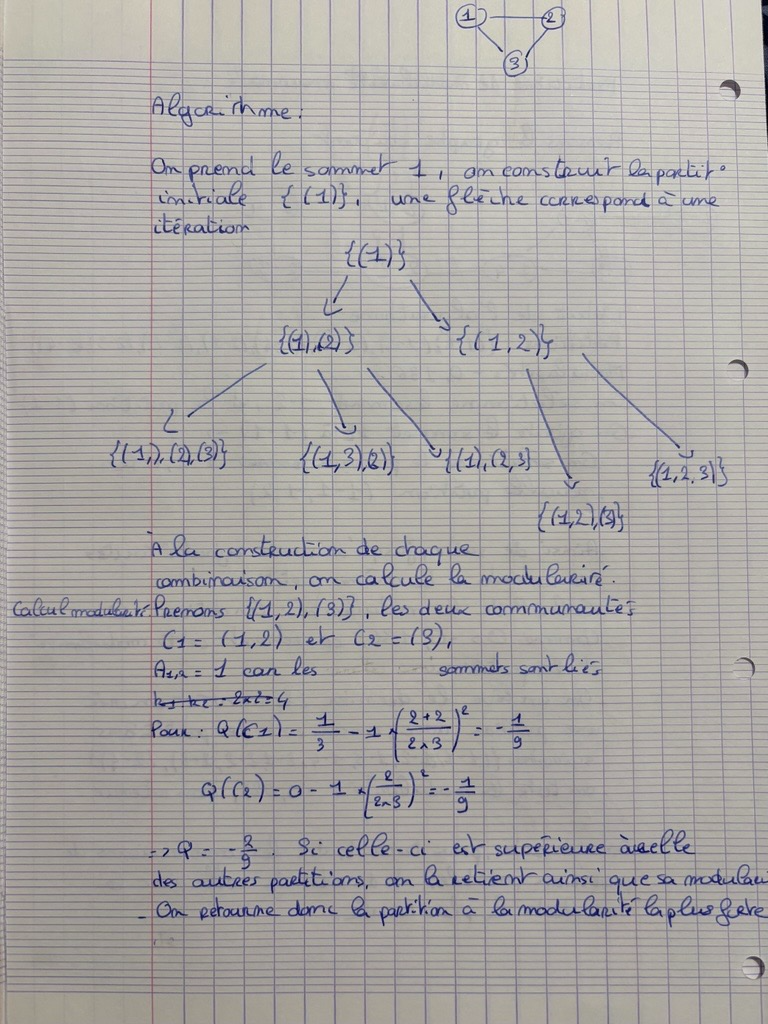

Girvan-Newman : Q = 0.5519, 3 communautés
Louvain       : Q = 0.5519, 3 communautés
Label Prop. Simple   : Q = 0.5519, 3 communautés
Label Prop. Stabilisé: Q = 0.5519, 3 communautés


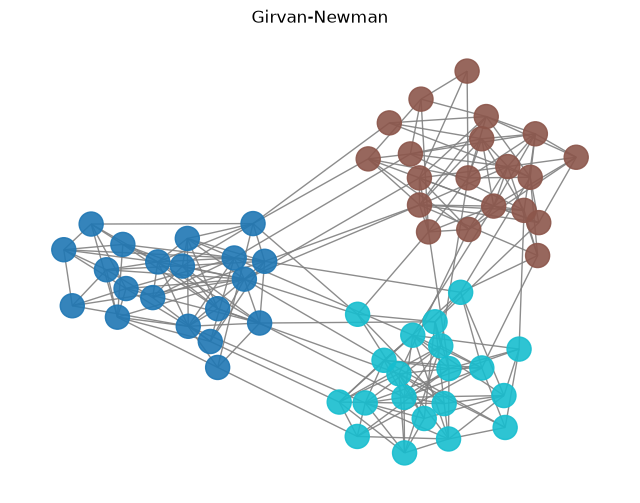

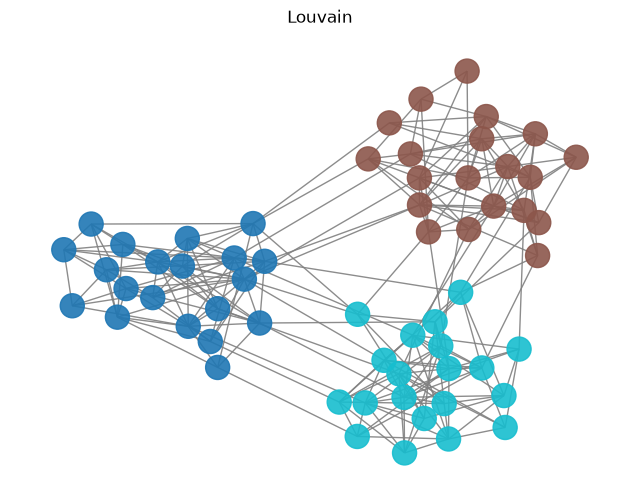

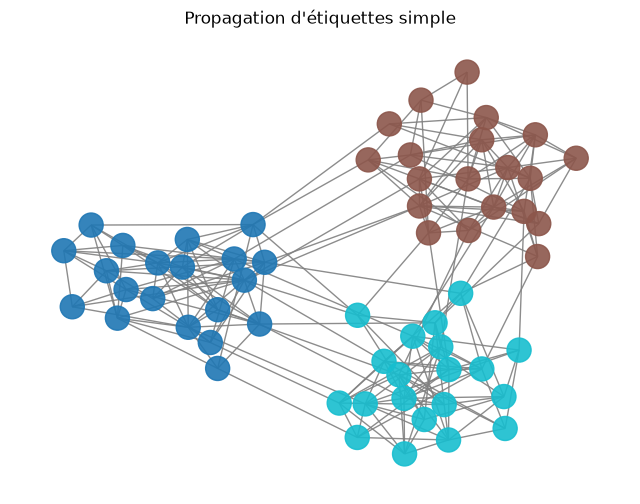

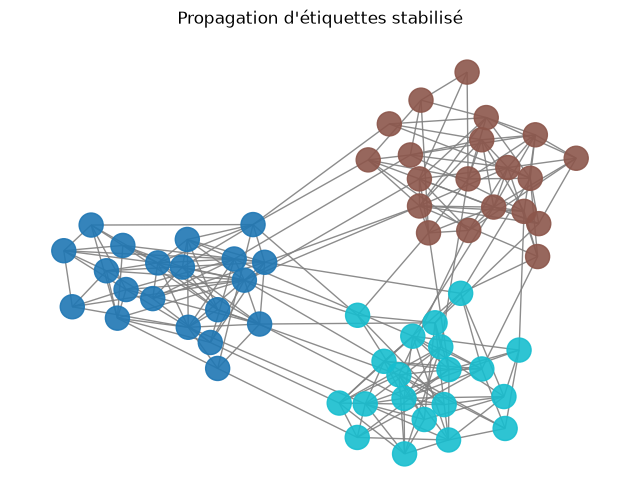

In [8]:
# Graphe à communautés plantées
G, som_comm = generate_planted_partition_graph(
    n=60, n_com=3, p_in=0.35, p_out=0.03, seed=42
)

# Détection par Girvan-Newman
com_gn = girvan_newman_communities(G, n_communities=3)
Q_gn = modularity(G, com_gn)
print(f"Girvan-Newman : Q = {Q_gn:.4f}, {len(com_gn)} communautés")

# Détection par Louvain
com_lv = louvain_communities(G)
Q_lv = modularity(G, com_lv)
print(f"Louvain       : Q = {Q_lv:.4f}, {len(com_lv)} communautés")

# Détection par propagation d'étiquettes simple
com_lp_si = label_propagation_communities_simple(G)
Q_lp_si = modularity(G, com_lp_si)
print(f"Label Prop. Simple   : Q = {Q_lp_si:.4f}, {len(com_lp_si)} communautés")

# Détection par propagation d'étiquettes stabilized
com_lp_st = label_propagation_communities_stabilized(G)
Q_lp_st = modularity(G, com_lp_st)
print(f"Label Prop. Stabilisé: Q = {Q_lp_st:.4f}, {len(com_lp_st)} communautés")

# Visualisation
plot_communities(G, com_gn, title="Girvan-Newman")
plot_communities(G, com_lv, title="Louvain")
plot_communities(G, com_lp_si, title="Propagation d'étiquettes simple")
plot_communities(G, com_lp_st, title="Propagation d'étiquettes stabilisé")



## 3. Le jeu de données Cora

Pour permettre la comparaison des résultats entre binômes, le jeu de
données Cora est imposé pour la partie comparative. Il s'agit d'un réseau
de citations extrait de publications en apprentissage automatique : chaque
sommet est un article, chaque arête une citation, et chaque article est
étiqueté par un domaine scientifique. Cette étiquette fournit la partition
de référence, qui permet de mesurer la qualité des partitions détectées
par l'information mutuelle normalisée (NMI), en complément de la
modularité.

| Caractéristique | Valeur |
|---|---|
| Sommets | 2 708 |
| Arêtes | 5 429 |
| Classes | 7 |

Source : \url{https://linqs-data.soe.ucsc.edu/public/lbc/cora.tgz}

Vous êtes libres de tester vos algorithmes sur d'autres jeux de données
réels, par exemple ceux de la collection SNAP, pourvu que Cora reste le
point de comparaison commun. Dans ce cas, précisez la source et la nature
de la partition de référence si elle existe.

In [9]:
from projet_A2026_utils import load_cora

Graphe : 2708 sommets, 5278 arêtes
Communautés de référence : 7
Louvain : Q = 0.8158


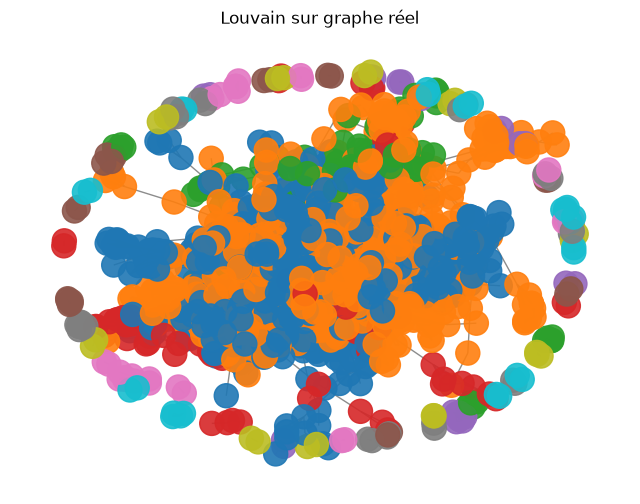

In [10]:
# Exemple : graphe Cora
#G_real, ground_truth = load_real_graph("cora")
G_real, ground_truth = load_cora()

print(f"Graphe : {G_real.number_of_nodes()} sommets, "
      f"{G_real.number_of_edges()} arêtes")
print(f"Communautés de référence : {len(set(ground_truth.values()))}")

# Détection avec Louvain
com_lv_real = louvain_communities(G_real)
Q_lv_real = modularity(G_real, com_lv_real)
print(f"Louvain : Q = {Q_lv_real:.4f}")

plot_communities(G_real, com_lv_real, title="Louvain sur graphe réel")


## 4. Comparaison expérimentale

### 4.1 Protocole

Nous faisons varier la taille des graphes synthétiques (de 20 à quelques
milliers de sommets) et, pour chaque taille, nous exécutons chaque algorithme
plusieurs fois en mesurant le temps d'exécution et la modularité obtenue. Pour
les graphes avec communautés de référence, nous mesurons également l'information
mutuelle normalisée (NMI) entre la partition détectée et la partition attendue.

### 4.2 Temps d'exécution

[Courbes temps en fonction de la taille, échelles linéaire et/ou logarithmique,
comparaison avec les complexités théoriques.]

### 4.3 Qualité de la partition

[Courbes modularité et NMI en fonction de la taille ou du bruit.]

### 4.4 Compromis temps / qualité

[Discussion des cas où une heuristique rapide atteint une qualité comparable à
une heuristique lente, et inversement.]

[Girvan-Newman] Temps moyen de 123.37s pour n=200 (> 20s) : arrêté pour les tailles supérieures.


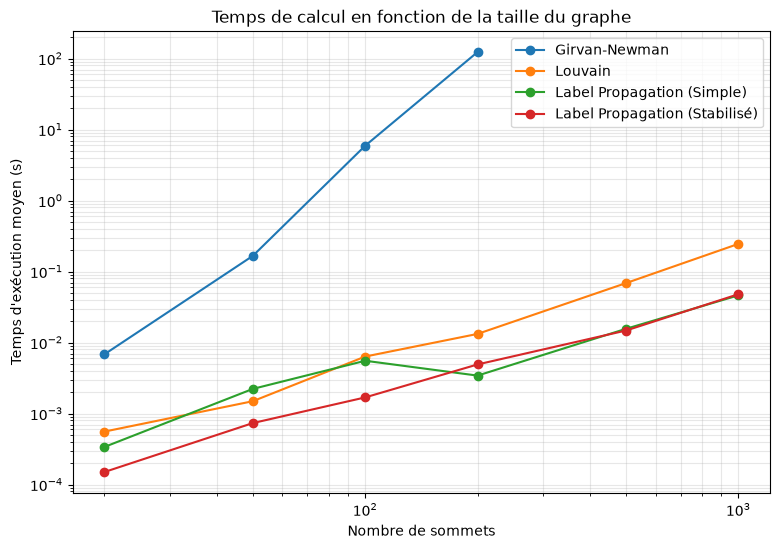

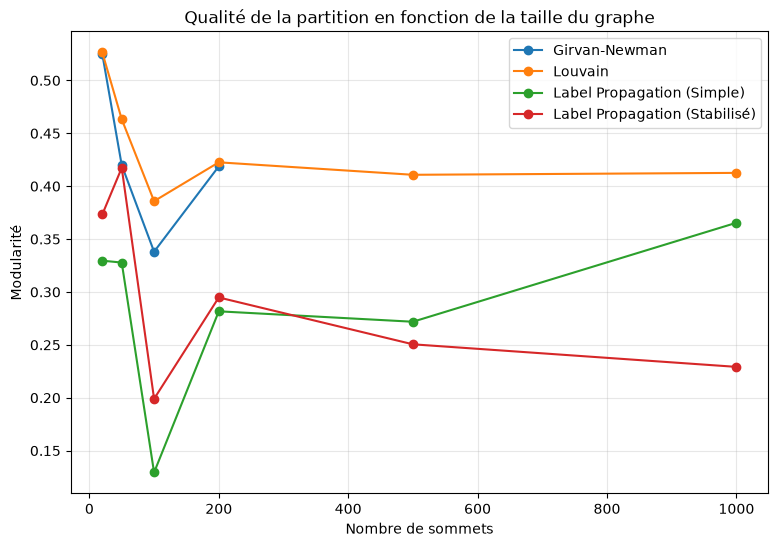

In [16]:
sizes = [20, 50, 100, 200, 500, 1000]
results = {}
timed_out = set()
MAX_TIME_PER_ALGO = 20  # Seuil en secondes au-delà duquel un algorithme n'est plus testé pour les tailles supérieures

for n in sizes:
    G, som_comm = generate_planted_partition_graph(
        n=n, n_com=4, p_in=0.3, p_out=0.05, seed=n
    )
    for name, fn in [
        ("Girvan-Newman", girvan_newman_communities),
        ("Louvain", louvain_communities),
        ("Label Propagation (Simple)", label_propagation_communities_simple),
        ("Label Propagation (Stabilisé)", label_propagation_communities_stabilized),
    ]:
        if name in timed_out:
            continue

        repeats = 1 if name == "Girvan-Newman" else 3
        t, q = benchmark_communities(G, fn, repeats=repeats)
        results.setdefault(name, []).append((n, t, q))

        if t > MAX_TIME_PER_ALGO:
            print(f"[{name}] Temps moyen de {t:.2f}s pour n={n} (> {MAX_TIME_PER_ALGO}s) : arrêté pour les tailles supérieures.")
            timed_out.add(name)

# Tracé temps
plt.figure(figsize=(9, 6))
for name, vals in results.items():
    ns, ts, qs = zip(*vals)
    plt.plot(ns, ts, marker='o', label=name)
plt.xlabel("Nombre de sommets")
plt.ylabel("Temps d'exécution moyen (s)")
plt.xscale("log")
plt.yscale("log")
plt.title("Temps de calcul en fonction de la taille du graphe")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

# Tracé modularité
plt.figure(figsize=(9, 6))
for name, vals in results.items():
    ns, ts, qs = zip(*vals)
    plt.plot(ns, qs, marker='o', label=name)
plt.xlabel("Nombre de sommets")
plt.ylabel("Modularité")
plt.title("Qualité de la partition en fonction de la taille du graphe")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## 5. Conclusion

### 5.1 Synthèse

[Rappeler les écarts observés entre algorithmes, en reliant chaque observation
à la complexité théorique correspondante. Discuter des cas où la modularité
seule est un indicateur trompeur.]

### 5.2 Apports du projet

[Analyse réflexive : qu'avez-vous compris de la notion de complexité, de la
différence entre exact et approché, du rôle des heuristiques et des limites de
la modularité ?]